# Demo: what the committed results say

This notebook reads only files committed under `results/`. It needs no data
download, no model and no GPU, and runs in a minute on a laptop.

Scope: HotpotQA, MuSiQue and 2WikiMultihopQA distractor pools (the gold
paragraphs plus the dataset's distractors, not open Wikipedia), one 7B model
(Qwen2.5-7B-Instruct, 4-bit, MLX), one Mac. The confirmation folds are
`results/folds/*_confirm.txt` (n=1000 each); the exploration folds are dev
positions 0-499.

Four things are shown:

1. the 2x2 of answer against evidence, recomputed from a run's per-question file
2. the decomposition of the "answer right, gold evidence incomplete" cell
3. per-hop retrieval precision and recall of the ircot runs
4. where the agent's wrong answers are lost (exploration only; nothing about
   the agent is a result before its confirmation run)

In [1]:
from pathlib import Path
import json, math
import pandas as pd
import matplotlib.pyplot as plt

R = Path('results') if Path('results').is_dir() else Path('..') / 'results'
pd.set_option('display.width', 160)

def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

## 1. The 2x2: answer right or wrong, gold evidence complete or not

"Retrieval correct" means every annotated gold sentence reached the context the
model read. The cell of interest is answer right (EM) with that evidence
incomplete. Recomputed here from each run's `_qa.csv` and checked against the
committed decomposition table.

In [2]:
runs = ['bm25_hotpot_confirm', 'bm25_k13_hotpot_confirm', 'hybrid_ircot_hotpot_confirm',
        'hybrid_ircot_rerank_hotpot_confirm']
dec = pd.read_csv(R / 'hotpot_confirm_decomposition.csv').set_index('run')
rows = []
for run in runs:
    qa = pd.read_csv(R / f'{run}_qa.csv')
    right, full = qa.em > 0, qa.retrieval_correct > 0
    n, cell = len(qa), int((right & ~full).sum())
    lo, hi = wilson(cell, n)
    rows.append({'run': run, 'n': n,
                 'right, complete': int((right & full).sum()), 'right, incomplete': cell,
                 'wrong, complete': int((~right & full).sum()), 'wrong, incomplete': int((~right & ~full).sum()),
                 'cell share': round(cell / n, 3), 'Wilson 95%': f'[{lo:.3f}, {hi:.3f}]'})
    assert abs(cell / n - dec.loc[run, 'illusion']) < 1e-9, run
two_by_two = pd.DataFrame(rows).set_index('run')
two_by_two

,n,"right, complete","right, incomplete","wrong, complete","wrong, incomplete",cell share,Wilson 95%
run,,,,,,,
bm25_hotpot_confirm,1000,284,131,218,367,0.131,"[0.111, 0.153]"
bm25_k13_hotpot_confirm,1000,335,106,275,284,0.106,"[0.088, 0.127]"
hybrid_ircot_hotpot_confirm,1000,406,60,368,166,0.060,"[0.047, 0.076]"
hybrid_ircot_rerank_hotpot_confirm,1000,378,106,279,237,0.106,"[0.088, 0.127]"


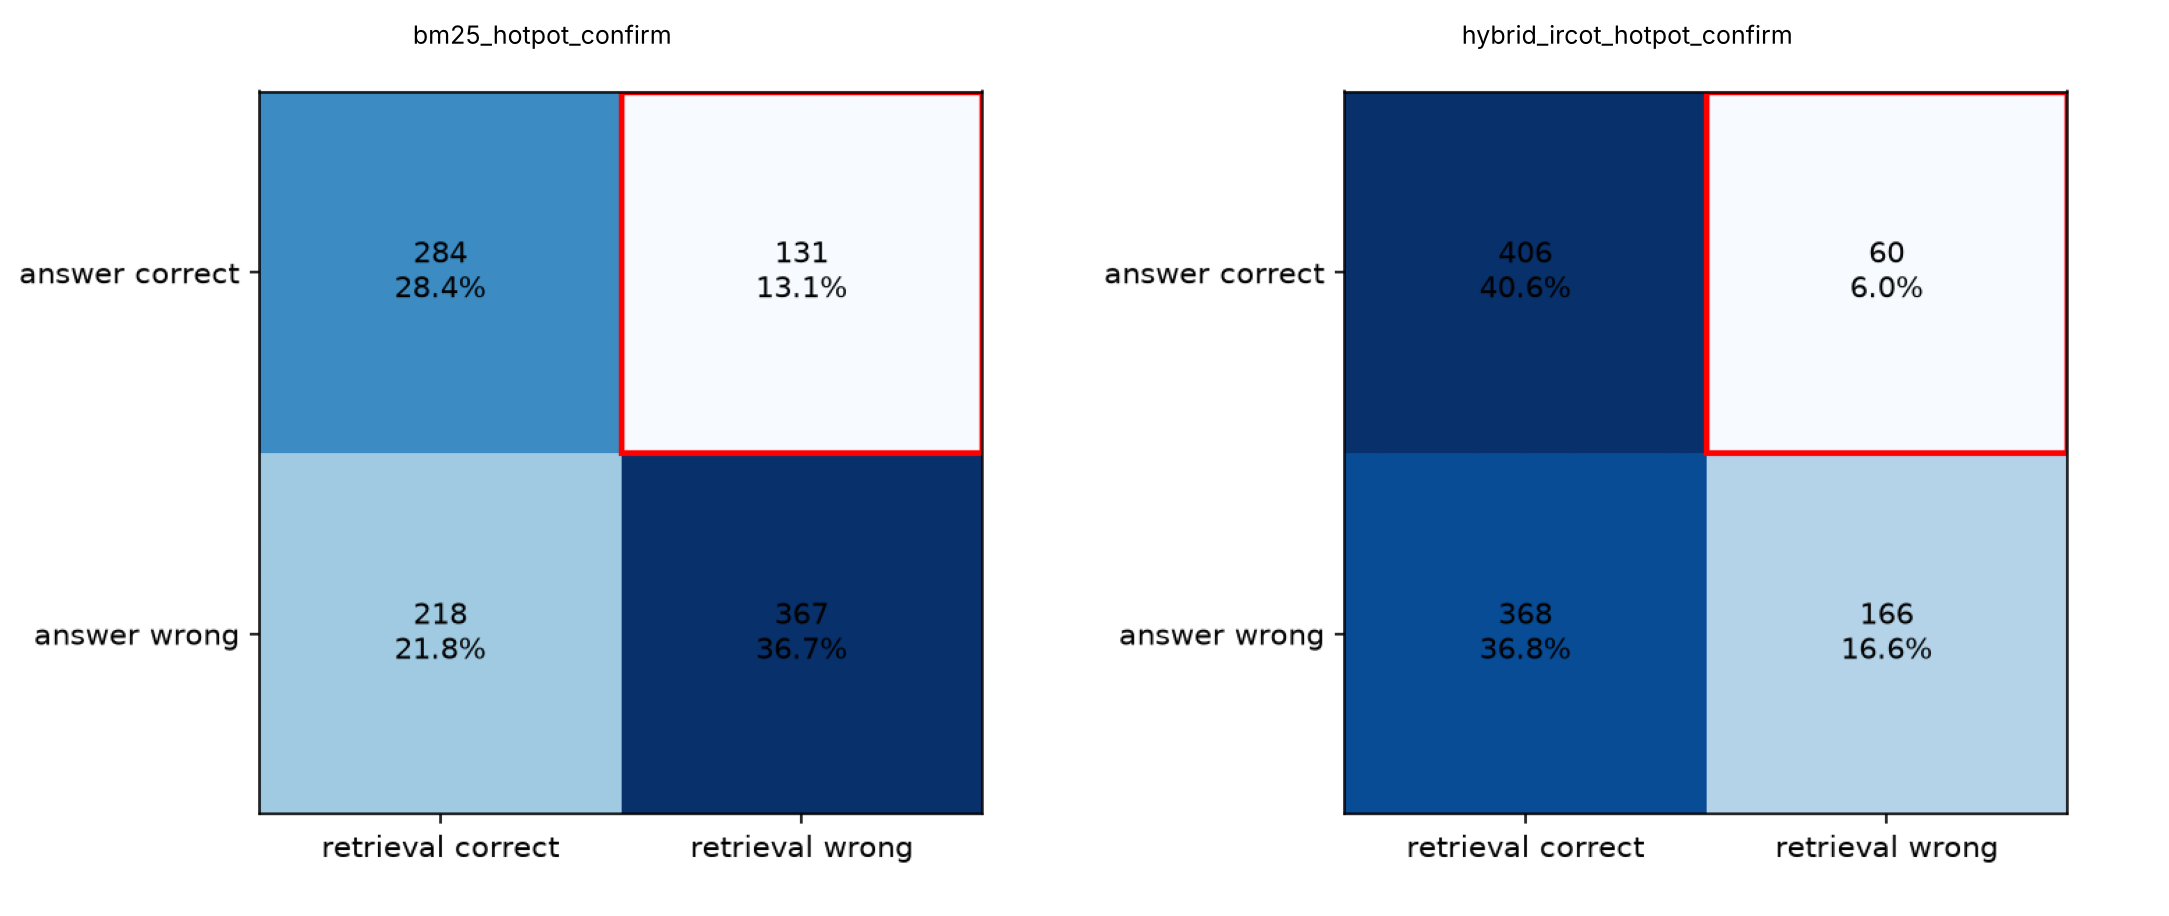

In [3]:
from matplotlib.image import imread
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, run in zip(axes, ['bm25_hotpot_confirm', 'hybrid_ircot_hotpot_confirm']):
    ax.imshow(imread(R / f'{run}_2x2.png'))
    ax.set_title(run, fontsize=9)
    ax.axis('off')
plt.tight_layout()

## 2. What the cell is made of

Each question in the cell is put in the first bucket that holds
(`src/eval/analyze.py`): parametric (closed book right too), yes/no,
shortcut (the answer sentence reached the model, the bridge fact did not),
paragraph, partial, none. Confirmation folds, n=1000 per run.

In [4]:
cols = ['n', 'em', 'retrieval_correct', 'illusion', 'illusion_lo', 'illusion_hi',
        'parametric', 'yesno', 'shortcut', 'paragraph', 'partial', 'none']
tabs = []
for ds in ('hotpot', 'musique', '2wiki'):
    t = pd.read_csv(R / f'{ds}_confirm_decomposition.csv')
    t.insert(0, 'dataset', ds)
    tabs.append(t)
decomp = pd.concat(tabs).set_index(['dataset', 'run'])[cols]
decomp

n     em  retrieval_correct  illusion  illusion_lo  illusion_hi  parametric  yesno  shortcut  paragraph  \
dataset run                                                                                                                                              
hotpot  bm25_hotpot_confirm                 1000  0.415              0.502     0.131       0.1115       0.1533          42      2        81          3   
        bm25_k13_hotpot_confirm             1000  0.441              0.610     0.106       0.0884       0.1266          30      2        69          4   
        hybrid_ircot_hotpot_confirm         1000  0.466              0.774     0.060       0.0469       0.0765          18      1        40          0   
        hybrid_ircot_rerank_hotpot_confirm  1000  0.484              0.657     0.106       0.0884       0.1266          24      1        76          2   
musique bm25_musique_confirm                1000  0.138              0.169     0.078       0.0629       0.0963           9      0        67          0   
        bm25_k7_musique_confirm             1000  0.152              0.243     0.073       0.0585       0.0908           8      0        64          0   
        hybrid_musique_confirm              1000  0.173              0.278     0.074       0.0594       0.0919           7      0        64          0   
        hybrid_ircot_musique_confirm        1000  0.223              0.553     0.051       0.0390       0.0664           6      0        45          0   
2wiki   bm25_2wiki_confirm                  1000  0.320              0.365     0.133       0.1134       0.1555          56      0        57          8   
        bm25_k13_2wiki_confirm              1000  0.349              0.491     0.102       0.0847       0.1223          44      0        38         15   

                                            partial  none  
dataset run                                                
hotpot  bm25_hotpot_confirm                       3     0  
        bm25_k13_hotpot_confirm                   1     0  
        hybrid_ircot_hotpot_confirm               1     0  
        hybrid_ircot_rerank_hotpot_confirm        3     0  
musique bm25_musique_confirm                      2     0  
        bm25_k7_musique_confirm                   1     0  
        hybrid_musique_confirm                    3     0  
        hybrid_ircot_musique_confirm              0     0  
2wiki   bm25_2wiki_confirm                        9     3  
        bm25_k13_2wiki_confirm                    4     1

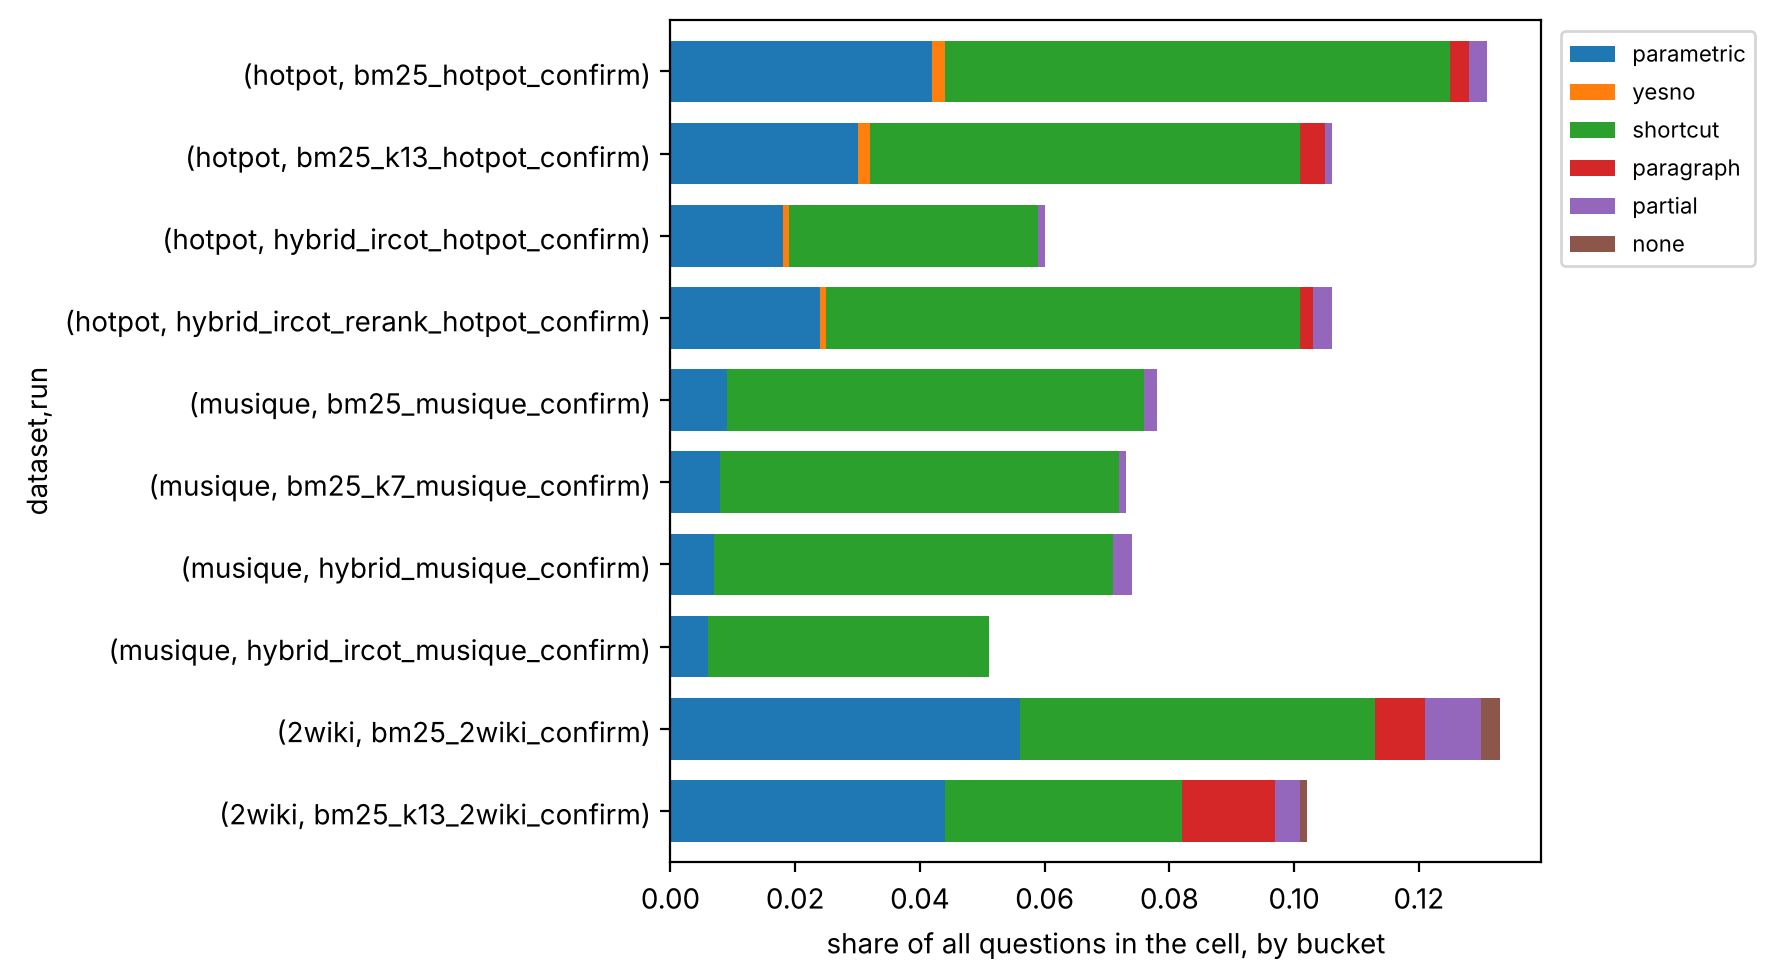

In [5]:
b = ['parametric', 'yesno', 'shortcut', 'paragraph', 'partial', 'none']
share = decomp[b].div(decomp['n'], axis=0)
ax = share.plot.barh(stacked=True, figsize=(9, 5), width=0.75)
ax.set_xlabel('share of all questions in the cell, by bucket')
ax.invert_yaxis()
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()

## 3. Per-hop retrieval of the ircot runs

Sentence-level precision and recall of each hop's top 10 against the gold
sentences, and the recall of everything retrieved up to that hop. `n` is how
many questions reached the hop. 2wiki has no ircot run on its confirmation
fold (only bm25 at k=10 and k=13), so it is not drawn.

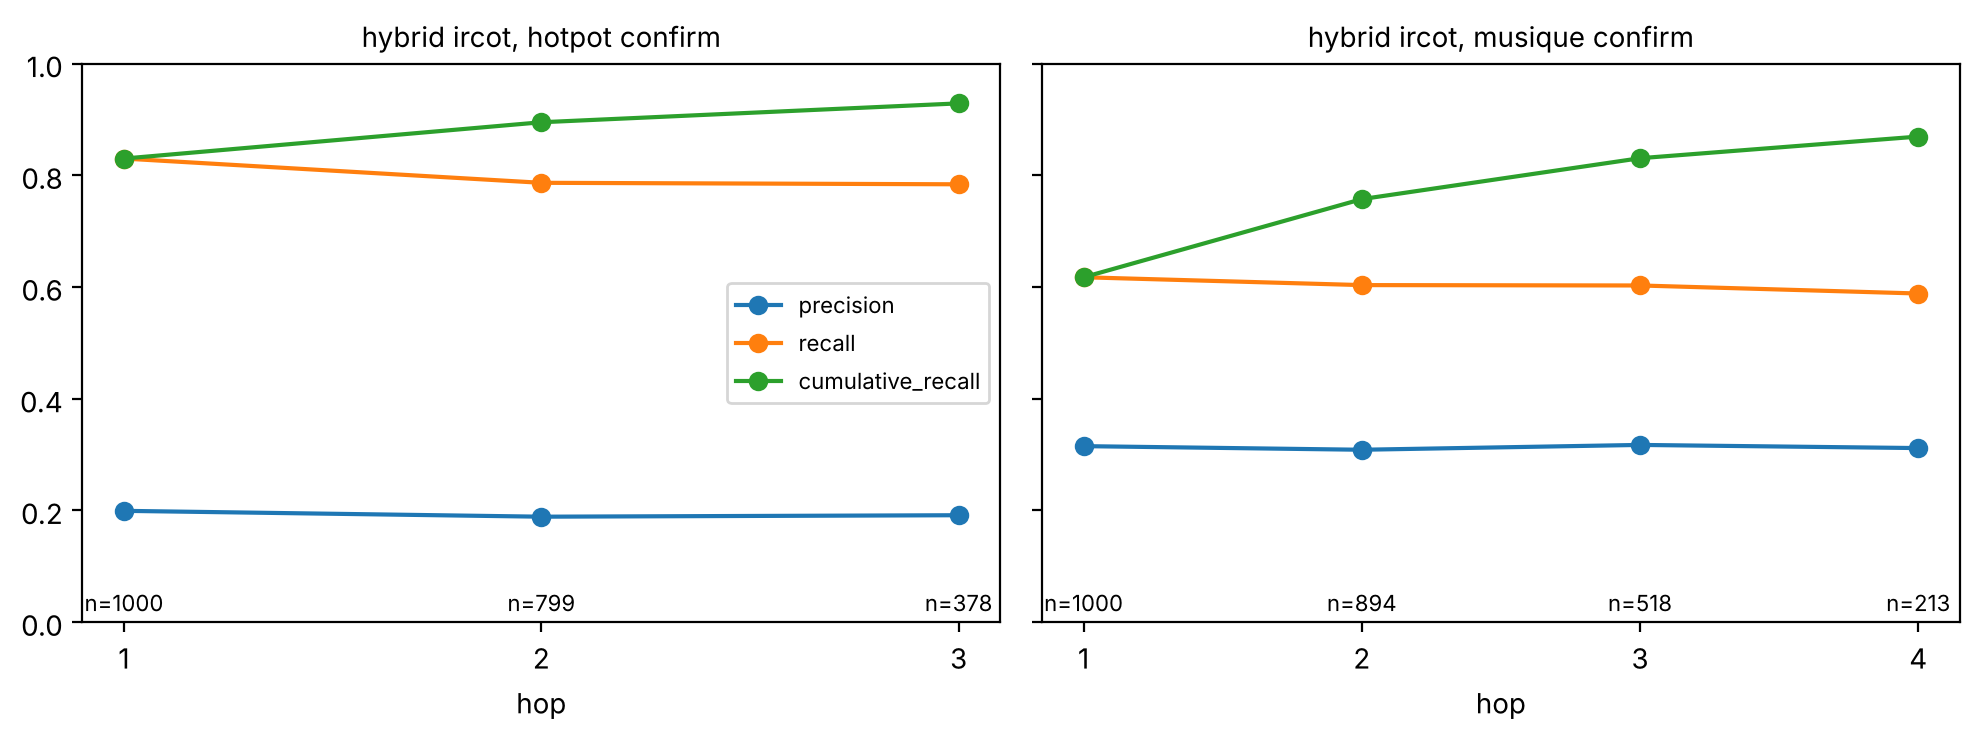

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, ds in zip(axes, ('hotpot', 'musique')):
    ph = json.loads((R / f'hybrid_ircot_{ds}_confirm_per_hop.json').read_text())
    hops = sorted(ph, key=int)
    x = [int(h) + 1 for h in hops]
    for key in ('precision', 'recall', 'cumulative_recall'):
        ax.plot(x, [ph[h][key] for h in hops], marker='o', label=key)
    for xi, h in zip(x, hops):
        ax.annotate(f"n={ph[h]['n']}", (xi, 0.02), ha='center', fontsize=8)
    ax.set_title(f'hybrid ircot, {ds} confirm', fontsize=10)
    ax.set_xlabel('hop')
    ax.set_xticks(x)
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=8)
plt.tight_layout()

## 4. Where the agent's wrong answers are lost (exploration only)

The main agent over subagents as it stands after the Stage 6b rounds
(`orchestrator_guard_wide_unsup_keepans_thin`), on the two folds its changes
were chosen on: hotpot exploration (dev 0-499) and `hotpot_train_hard`. Every
wrong answer is placed by where the gold answer string was: in what the final
read was given, retrieved and not kept (dropped), never retrieved, or a yes/no
gold. These numbers were used to choose the changes, so they are optimistic
and are not results; the confirmation run is in `docs/plan.md`.

In [7]:
keep = ['n', 'em', 'f1', 'wrong', 'in_context', 'dropped', 'not_retrieved', 'yesno_gold',
        'em_in_context', 'gen_calls', 'notebook_size']
tabs = []
for fold in ('explore', 'train_hard'):
    t = pd.read_csv(R / f'agent_dev4_both_hotpot_{fold}_losses.csv')
    t = t[t.run.str.contains('keepans_thin')]
    t.insert(0, 'fold', fold)
    tabs.append(t)
losses = pd.concat(tabs).set_index('fold')[keep]
losses

,n,em,f1,wrong,in_context,dropped,not_retrieved,yesno_gold,em_in_context,gen_calls,notebook_size
fold,,,,,,,,,,,
explore,500,0.576,0.6851,212,149,32,28,3,0.6228,7.73,3.854
train_hard,500,0.536,0.6813,232,167,36,28,1,0.5866,7.86,3.870


In [8]:
never = pd.read_csv(R / 'agent_misses_hotpot_explore_never.csv').set_index('miss')
never[['n', 'named_question', 'named_lookup', 'named_query', 'named_answer_only', 'named_never',
       'sentence_not_first', 'neighbour_retrieved']]

,n,named_question,named_lookup,named_query,named_answer_only,named_never,sentence_not_first,neighbour_retrieved
miss,,,,,,,,
title,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
not_in_pool,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
para_partly,18,4.0,1.0,2.0,4.0,7.0,14.0,15.0
para_unseen,6,0.0,0.0,0.0,1.0,5.0,2.0,0.0
all,28,4.0,1.0,2.0,5.0,12.0,16.0,15.0


The second table splits the never-retrieved answers of the exploration run
(`src/eval/agent_misses.py`): a retrieved paragraph's title, a gold paragraph
retrieved without its answer sentence, or a paragraph never retrieved, with
where that paragraph was first named. `docs/plan.md` (Stage 6b, From the
traces) reads it.